# **Finding Duplicates Lab**


## Introduction


Data wrangling is a critical step in preparing datasets for analysis, and handling duplicates plays a key role in ensuring data accuracy. In this lab, you will focus on identifying and removing duplicate entries from your dataset. 


## Objectives


In this lab, you will perform the following:


1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.


## Hands on Lab


Install the needed library


Import pandas module


In [2]:
import pandas as pd

Import matplotlib


In [3]:
import matplotlib.pyplot as plt

## **Load the dataset into a dataframe**


<h2>Read Data</h2>
<p>
We utilize the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


In [4]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)

# Display the first few rows
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

Load the data into a pandas dataframe:



Note: If you are working on a local Jupyter environment, you can use the URL directly in the pandas.read_csv() function as shown below:



In [5]:
# df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")

## Identify and Analyze Duplicates


### Task 1: Identify Duplicate Rows
1. Count the number of duplicate rows in the dataset.
3. Display the first few duplicate rows to understand their structure.


In [6]:
# 1. Contamos cuántas filas duplicadas exactas existen en el dataset
num_duplicates = df.duplicated().sum()
print(f"Número total de filas duplicadas: {num_duplicates}")

# 2. Filtramos el DataFrame para mostrar las primeras filas que son duplicadas
duplicate_rows = df[df.duplicated(keep="first")]
print("\nPrimeras filas duplicadas encontradas:")
duplicate_rows.head()

Número total de filas duplicadas: 20
Primeras filas duplicadas encontradas:

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
65437,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65438,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
65439,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
65440,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
65441,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 2: Analysis of Duplicate Response Patterns
1. Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork.
2. Clarify that these represent multiple respondents with identical answers rather than duplicate records. Analyse which other columns frequently share identical values within these response-pattern groups.
   


In [7]:
# 1. Agrupamos por las columnas indicadas para contar patrones de respuestas idénticas
selected_cols = ["MainBranch", "Employment", "RemoteWork"]
pattern_counts = (
    df.groupby(selected_cols).size().reset_index(name="Frecuencia")
)

# Ordenamos de mayor a menor para ver las combinaciones más comunes
top_patterns = pattern_counts.sort_values(by="Frecuencia", ascending=False)
print("Patrones de respuesta más frecuentes en las columnas seleccionadas:")
print(top_patterns.head())

# 2. Analizamos qué otras columnas comparten valores dentro del grupo con el patrón más común
# Tomamos la combinación más frecuente
most_common = top_patterns.iloc[0]

# Filtramos el DataFrame con esa combinación específica de respuestas
filtered_df = df[
    (df["MainBranch"] == most_common["MainBranch"])
    & (df["Employment"] == most_common["Employment"])
    & (df["RemoteWork"] == most_common["RemoteWork"])
]

# Analizamos qué otros atributos se repiten mucho dentro de este grupo (ej. Country y EdLevel)
print("\nDistribución de 'Country' dentro de este patrón de respuesta:")
print(filtered_df["Country"].value_counts().head())

print("\nDistribución de 'EdLevel' dentro de este patrón de respuesta:")
print(filtered_df["EdLevel"].value_counts().head())

Patrones de respuesta más frecuentes en las columnas seleccionadas:
                        MainBranch  \
0   I am a developer by profession   
2   I am a developer by profession   
1   I am a developer by profession   
78  I am a developer by profession   
8   I am a developer by profession   

                                           Employment  \
0                                 Employed, full-time   
2                                 Employed, full-time   
1                                 Employed, full-time   
78  Independent contractor, freelancer, or self-em...   
8   Employed, full-time;Independent contractor, fr...   

                              RemoteWork  Frecuencia  
0   Hybrid (some remote, some in-person)       15288  
2                                 Remote       12196  
1                              In-person        7118  
78                                Remote        2815  
8                                 Remote        1754  

Distribución de 'Country' den

### Task 3: Visualize Shared Response Patterns
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.


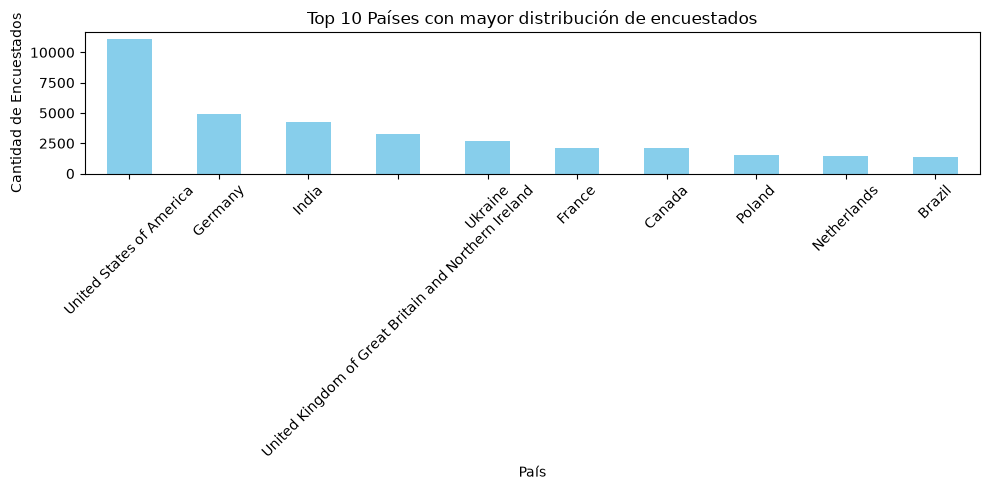

/tmp/ipykernel_301/1152111569.py:24: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

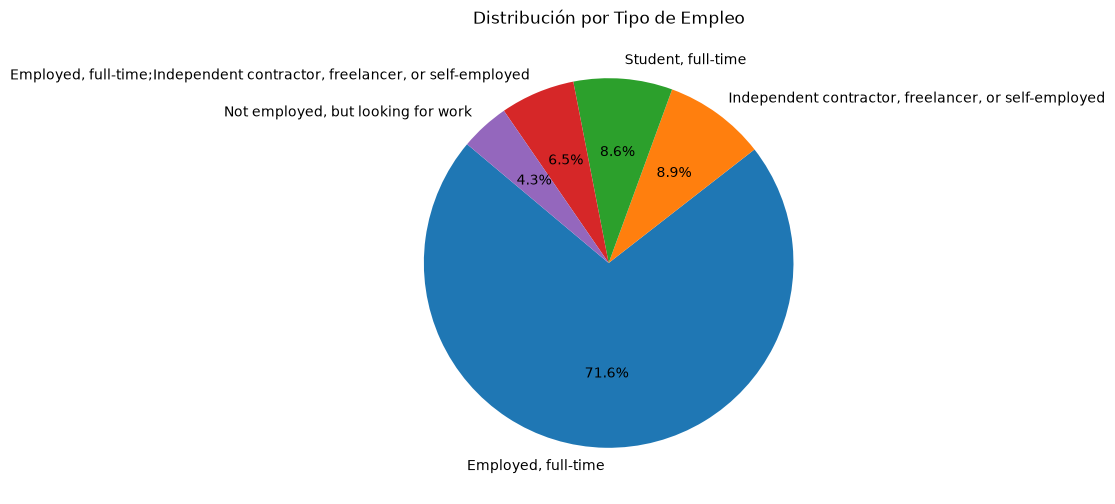

In [8]:
import matplotlib.pyplot as plt

# 1. Agrupamos por Country y contamos los encuestados con patrones compartidos
country_counts = df.groupby('Country').size().nlargest(10)

# Gráfico de barras para los 10 países principales
plt.figure(figsize=(10, 5))
country_counts.plot(kind='bar', color='skyblue')
plt.title('Top 10 Países con mayor distribución de encuestados')
plt.xlabel('País')
plt.ylabel('Cantidad de Encuestados')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Agrupamos por Employment para ver el tipo de empleo
employment_counts = df['Employment'].value_counts().head(5)

# Gráfico de pastel para la distribución de empleo
plt.figure(figsize=(6, 6))
employment_counts.plot(kind='pie', autopct='%1.1f%%', startangle=140)
plt.title('Distribución por Tipo de Empleo')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


## Verify and Document Duplicate Removal Process


### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


### Summary and Next Steps
**In this lab, you focused on identifying and analyzing duplicate rows within the dataset.**

- You employed various techniques to explore the nature of duplicates and applied strategic methods for their removal.
- For additional analysis, consider investigating the impact of duplicates on specific analyses and how their removal affects the results.
- This version of the lab is more focused on duplicate analysis and handling, providing a structured approach to deal with duplicates in a dataset effectively.
